<a href="https://colab.research.google.com/github/reginamtxg/M-todos-num-ricos-I/blob/main/DifDiv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#$\color{#F59E0B}{\Large \textbf{Diferencias divididas}}$
# algoritmo 3.2 | codigo  
*García Martínez Regina*

Para obtener los coeficientes de diferencia dividida del polinomio $P$ de interpolación en los $n+1$ números distintos $x_0, x_1,...,x_n$ para la función $f$:

*ENTRADA* números $x_0, x_1,...,x_n$; valores $f(x_0), f(x_1),...,f(x_n)$ como $F_{0,0}, F_{1,0},..., F_{n,0}$

*SALIDA* los números $F_{0,0}, F_{1,1},..., F_{n,n}$ donde
$$P_n(x) = F_{0,0} + \sum_{i=1}^{n} F_{i,i} \prod_{j=0}^{i-1} (x - x_j)$$

F_{0,0} = 0.7651977
F_{1,1} = -0.4837057
F_{2,2} = -0.1087339
F_{3,3} = 0.0658784
F_{4,4} = 0.0018251
Polinomio de Newton:
P(x) = -0.483705666666666*x + 0.00182510288066044*(x - 1.9)*(x - 1.6)*(x - 1.3)*(x - 1.0) + 0.0658783950617283*(x - 1.6)*(x - 1.3)*(x - 1.0) - 0.108733888888889*(x - 1.3)*(x - 1.0) + 1.24890336666667
P(x) expandido = 0.00182510288066044*x**4 + 0.0552927983538978*x**3 - 0.343046604938247*x**2 + 0.0733913477366034*x + 0.977735055967085


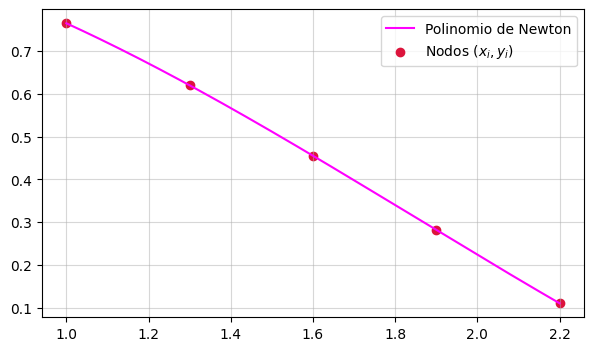

In [16]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

def diferencias_divididas_newton(x_nodos, y_nodos):
    n = len(x_nodos) - 1
    xs = [sp.Float(val) for val in x_nodos]
    F = [[sp.Float(0) for _ in range(n + 1)] for _ in range(n + 1)]
    for i in range(n + 1):
        F[i][0] = sp.Float(y_nodos[i])

    for i in range(1, n + 1):
        for j in range(1, i + 1):
            F[i][j] = (F[i][j - 1] - F[i - 1][j - 1]) / (xs[i] - xs[i - j])

    coeficientes = [F[i][i] for i in range(n + 1)]
    return coeficientes

def construir_y_graficar_newton(x_nodos, y_nodos, coeficientes):
    x = sp.Symbol('x')
    P = coeficientes[0]
    producto = 1
    for i in range(1, len(coeficientes)):
        producto *= (x - sp.Float(x_nodos[i - 1]))
        P += coeficientes[i] * producto

    print("Polinomio de Newton:")
    print(f"P(x) = {P}")
    print(f"P(x) expandido = {sp.expand(P)}")

    P_num = sp.lambdify(x, P, 'numpy')
    x_graf = np.linspace(min(x_nodos), max(x_nodos), 150)
    y_graf = P_num(x_graf)

    plt.figure(figsize=(7, 4))
    plt.plot(x_graf, y_graf, color="magenta", label="Polinomio de Newton")
    plt.scatter(x_nodos, y_nodos, color="crimson", label="Nodos $(x_i, y_i)$")
    plt.legend()
    plt.grid(True, linestyle="-", alpha=0.5)
    plt.show()

    return P

x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

coeficientes = diferencias_divididas_newton(x_datos, y_datos)

for i, c in enumerate(coeficientes):
    print(f"F_{{{i},{i}}} = {float(c):.7f}")

P = construir_y_graficar_newton(x_datos, y_datos, coeficientes)